In [72]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [73]:
df = pd.read_table('data/학생공부시간 및 점수.txt', sep="\t")
df

,hour,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22
5,3.2,30
6,3.9,42
7,4.4,48
8,4.5,38
9,5.0,58


In [74]:
data = df.iloc[:,0].values 
label = df.iloc[:,1:].values

# # reshape 작업 진행 필요없음
# data = df.iloc[:,:-1].values 
# label = df.iloc[:,1:].values

# data = df['hour'].values
# label = df['score'].values

data
label

array([[ 10],
       [  8],
       [ 14],
       [ 26],
       [ 22],
       [ 30],
       [ 42],
       [ 48],
       [ 38],
       [ 58],
       [ 60],
       [ 72],
       [ 62],
       [ 68],
       [ 72],
       [ 58],
       [ 76],
       [ 86],
       [ 90],
       [100]])

In [75]:
data = data.reshape(-1, 1)
label = label.reshape(-1, 1)

data
label

array([[ 10],
       [  8],
       [ 14],
       [ 26],
       [ 22],
       [ 30],
       [ 42],
       [ 48],
       [ 38],
       [ 58],
       [ 60],
       [ 72],
       [ 62],
       [ 68],
       [ 72],
       [ 58],
       [ 76],
       [ 86],
       [ 90],
       [100]])

In [76]:
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data 
train_label

array([[ 26],
       [ 38],
       [100],
       [ 58],
       [ 72],
       [ 62],
       [ 10],
       [  8],
       [ 72],
       [ 60],
       [ 68],
       [ 22],
       [ 14],
       [ 86],
       [ 30]])

In [77]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)

# 데이터 예측 
predict = lr.predict(test_data)
print('예측점수 :', predict)

# 정확도 
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)

예측점수 : [[46.25283474]
 [76.31314837]
 [91.34330519]
 [73.09240048]
 [40.88492159]]
train 정확도 : 0.9617721182493618
test 정확도 : 0.8527322071052257


In [78]:
in_data = input(' 공부 시간을 입력하세요. 예)7, 10, ')
in_data = float(in_data)
predict = lr.predict([[in_data]])
print('예측점수 : ',predict)

예측점수 :  [[52.69433052]]


In [79]:
lr.coef_

array([[10.7358263]])

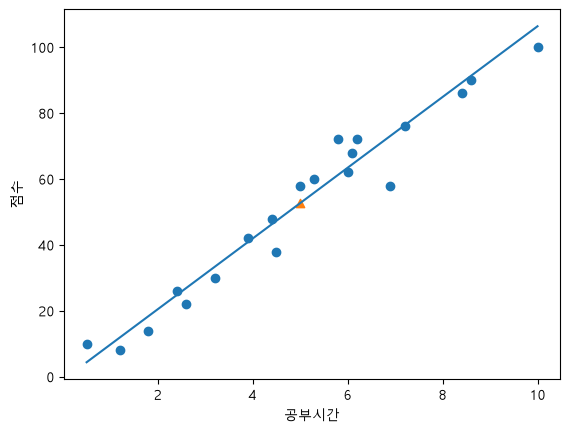

In [80]:
# 산점도 그래프
plt.scatter(data,label)
plt.scatter(in_data,predict, marker='^')
plt.plot([0.5,10],[0.5*lr.coef_[0]+lr.intercept_,10*lr.coef_[0]+lr.intercept_])  # 선그래프 # 배열이 두 번 [[]] 괄호로 싸여져 있기에 [0]으로 지정을 해야만 함. 그렇기에 미리 coef_ 값을 확인해야함
plt.xlabel("공부시간")
plt.ylabel("점수")
plt.show()